**Pet Adoption Speed Prediction Using Multimodal Data**

Project Overview

This project aims to predict pet adoption speed using three types of data: pet images, text descriptions, and tabular information.

Pretrained ResNet18 and Multilingual BERT are used to extract image and text features. Tabular data is processed using scaling and one-hot encoding.

Five models are compared: Image-only, Text-only, Tabular-only, Early Fusion, and Late Fusion.

The models are evaluated using Accuracy, Macro F1, Weighted F1, and Quadratic Weighted Kappa (QWK). Overfitting is also assessed by comparing training and validation performance.

In [2]:
# Import Libraries

import os
import random
import zipfile
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

# Set random seed for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Libraries imported successfully!")

Libraries imported successfully!


This step imports the Python libraries needed for data processing, feature extraction, model training, and evaluation. A random seed of 42 is used to make the results more reproducible.


In [3]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

data_path = Path("/content/drive/MyDrive/PetFinder")

print("CSV exists:", (data_path / "train.csv").exists())
print("Images ZIP exists:", (data_path / "train_images.zip").exists())

Mounted at /content/drive
CSV exists: True
Images ZIP exists: True


Google Drive is connected to load the PetFinder dataset and save the extracted features, trained models, and evaluation results.

In [4]:
# Load and Inspect Dataset

import zipfile

# Load tabular dataset
csv_path = data_path / "train.csv"
df = pd.read_csv(csv_path)

# Check dataset size
print("Dataset shape:", df.shape)

# Show first 5 rows
display(df.head())

# Check image files in ZIP
image_zip_path = data_path / "train_images.zip"

with zipfile.ZipFile(image_zip_path, "r") as z:
    image_files = [
        name for name in z.namelist()
        if name.lower().endswith((".jpg", ".jpeg", ".png"))
        and not name.startswith("__MACOSX/")
    ]

print("Number of images:", len(image_files))
print("First 5 image files:")
print(image_files[:5])

Dataset shape: (14993, 24)


,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,...,Health,Quantity,Fee,State,RescuerID,VideoAmt,Description,PetID,PhotoAmt,AdoptionSpeed
0,2,Nibble,3,299,0,1,1,7,0,1,...,1,1,100,41326,8480853f516546f6cf33aa88cd76c379,0,Nibble is a 3+ month old ball of cuteness. He ...,86e1089a3,1.0,2
1,2,No Name Yet,1,265,0,1,1,2,0,2,...,1,1,0,41401,3082c7125d8fb66f7dd4bff4192c8b14,0,I just found it alone yesterday near my apartm...,6296e909a,2.0,0
2,1,Brisco,1,307,0,1,2,7,0,2,...,1,1,0,41326,fa90fa5b1ee11c86938398b60abc32cb,0,Their pregnant mother was dumped by her irresp...,3422e4906,7.0,3
3,1,Miko,4,307,0,2,1,2,0,2,...,1,1,150,41401,9238e4f44c71a75282e62f7136c6b240,0,"Good guard dog, very alert, active, obedience ...",5842f1ff5,8.0,2
4,1,Hunter,1,307,0,1,1,0,0,2,...,1,1,0,41326,95481e953f8aed9ec3d16fc4509537e8,0,This handsome yet cute boy is up for adoption....,850a43f90,3.0,2


Number of images: 58311
First 5 image files:
['train_images/2d725d001-3.jpg', 'train_images/bf9bd91e1-1.jpg', 'train_images/9cb525274-3.jpg', 'train_images/16ffedcf8-7.jpg', 'train_images/a63364c39-1.jpg']


The PetFinder dataset is loaded from Google Drive. It contains 14,993 pets and 24 columns. We check the dataset size, column names, and data types. We also check the image files before starting the analysis.

In [5]:
# Check image files

print("Number of images:", len(image_files))
print("First 5 image files:")
print(image_files[:5])

Number of images: 58311
First 5 image files:
['train_images/2d725d001-3.jpg', 'train_images/bf9bd91e1-1.jpg', 'train_images/9cb525274-3.jpg', 'train_images/16ffedcf8-7.jpg', 'train_images/a63364c39-1.jpg']


In [6]:
# Data Quality Assessment

# Check missing values
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Check duplicates
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate PetIDs:", df["PetID"].duplicated().sum())

# Check target distribution
print("\nAdoptionSpeed distribution:")
print(df["AdoptionSpeed"].value_counts().sort_index())

Missing values:
Name           1265
Description      13
dtype: int64

Duplicate rows: 0
Duplicate PetIDs: 0

AdoptionSpeed distribution:
AdoptionSpeed
0     410
1    3090
2    4037
3    3259
4    4197
Name: count, dtype: int64


## Data Quality Assessment

We check missing values, duplicate records, and the distribution of AdoptionSpeed.

The dataset has 1,265 missing values in Name and 13 in Description. No duplicate rows or PetIDs were found.

The target classes are imbalanced, especially AdoptionSpeed 0, which has fewer samples than the other classes.

In [7]:
# Match Images with PetID

from pathlib import Path

# Extract PetID from image filenames
image_pet_ids = set()

for filename in image_files:
    pet_id = Path(filename).stem.rsplit("-", 1)[0]
    image_pet_ids.add(pet_id)

# Check which pets have images
df["HasImage"] = df["PetID"].astype(str).isin(image_pet_ids)

# Check which pets have descriptions
df["HasText"] = (
    df["Description"].notna()
    & df["Description"].fillna("").str.strip().ne("")
)

# Keep pets with both image and text
matched_df = df[
    df["HasImage"] & df["HasText"]
].copy()

# Check results
print("Total pets:", len(df))
print("Pets with images:", df["HasImage"].sum())
print("Pets with descriptions:", df["HasText"].sum())
print("Pets with both:", len(matched_df))

print("\nMatched dataset shape:", matched_df.shape)

Total pets: 14993
Pets with images: 14652
Pets with descriptions: 14980
Pets with both: 14640

Matched dataset shape: (14640, 26)


We use PetID to match the pet images with their text descriptions.

There are 14,652 pets with images and 14,980 pets with descriptions. We keep only pets with both types of data.

After filtering, 14,640 pets remain for the analysis. This allows us to compare the three modalities using the same pets.

In [8]:
# Train / Validation / Test Split

from sklearn.model_selection import train_test_split

# 70% training, 30% temporary
train_df, temp_df = train_test_split(
    matched_df,
    test_size=0.30,
    random_state=42,
    stratify=matched_df["AdoptionSpeed"]
)

# 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["AdoptionSpeed"]
)

# Reset index
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Check sizes
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Training: (10248, 26)
Validation: (2196, 26)
Testing: (2196, 26)


In [9]:
# Check Class Distribution

print("Training distribution:")
print(train_df["AdoptionSpeed"].value_counts(normalize=True).sort_index())

print("\nValidation distribution:")
print(val_df["AdoptionSpeed"].value_counts(normalize=True).sort_index())

print("\nTesting distribution:")
print(test_df["AdoptionSpeed"].value_counts(normalize=True).sort_index())

Training distribution:
AdoptionSpeed
0    0.026347
1    0.208626
2    0.272931
3    0.220238
4    0.271858
Name: proportion, dtype: float64

Validation distribution:
AdoptionSpeed
0    0.026412
1    0.208561
2    0.272769
3    0.220401
4    0.271858
Name: proportion, dtype: float64

Testing distribution:
AdoptionSpeed
0    0.026412
1    0.208561
2    0.273224
3    0.219945
4    0.271858
Name: proportion, dtype: float64


The dataset is divided into 70% training, 15% validation, and 15% testing data.

Stratified sampling is used to keep a similar distribution of AdoptionSpeed across the three datasets. A random seed of 42 is used for reproducibility.

The training set contains 10,248 pets, while the validation and test sets contain 2,196 pets each.

The test set is kept separate and only used for final evaluation.

In [10]:
# Step 6.2: Load Pretrained ResNet18

import torch
import torch.nn as nn

from torchvision.models import resnet18, ResNet18_Weights
from PIL import Image
from io import BytesIO

# Check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

# Load pretrained ResNet18
weights = ResNet18_Weights.DEFAULT

resnet = resnet18(weights=weights)

# Remove the final classification layer
resnet.fc = nn.Identity()

# Freeze pretrained model
for param in resnet.parameters():
    param.requires_grad = False

resnet = resnet.to(device)
resnet.eval()

# Image preprocessing
image_transform = weights.transforms()

print("ResNet18 loaded successfully!")

Device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 66.1MB/s]


ResNet18 loaded successfully!


In [11]:
# Rebuild image_map

from pathlib import Path
from collections import defaultdict
from PIL import Image
from io import BytesIO

# Create dictionary for pet images
image_map = defaultdict(list)

for filename in image_files:
    image_name = Path(filename).stem

    if "-" in image_name:
        pet_id, image_number = image_name.rsplit("-", 1)

        if image_number.isdigit():
            image_map[pet_id].append(filename)

# Check results
print("Number of pets with images:", len(image_map))

sample_pet_id = str(train_df.iloc[0]["PetID"])
print("Sample PetID:", sample_pet_id)
print("Sample images:", image_map[sample_pet_id][:3])

Number of pets with images: 14652
Sample PetID: 5cfd4e3bb
Sample images: ['train_images/5cfd4e3bb-9.jpg', 'train_images/5cfd4e3bb-8.jpg', 'train_images/5cfd4e3bb-10.jpg']


In [12]:
# Test Image Feature Extraction

# Select one pet from training data
sample_pet_id = str(train_df.iloc[0]["PetID"])

# Find the first image of this pet
sample_image_path = image_map[sample_pet_id][0]

# Read image from ZIP
with zipfile.ZipFile(data_path / "train_images.zip", "r") as z:
    image_bytes = z.read(sample_image_path)

image = Image.open(BytesIO(image_bytes)).convert("RGB")

# Preprocess image
image_tensor = image_transform(image)
image_tensor = image_tensor.unsqueeze(0).to(device)

# Extract image features
with torch.no_grad():
    image_features = resnet(image_tensor)

print("PetID:", sample_pet_id)
print("Image path:", sample_image_path)
print("Image feature shape:", image_features.shape)

PetID: 5cfd4e3bb
Image path: train_images/5cfd4e3bb-9.jpg
Image feature shape: torch.Size([1, 512])


In [13]:
# Combine Multiple Image Features

# Get all images for one pet
sample_image_paths = image_map[sample_pet_id]

image_feature_list = []

# Open ZIP file
with zipfile.ZipFile(data_path / "train_images.zip", "r") as z:

    for image_path in sample_image_paths:

        # Read image
        image_bytes = z.read(image_path)

        image = Image.open(
            BytesIO(image_bytes)
        ).convert("RGB")

        # Preprocess image
        image_tensor = image_transform(image)
        image_tensor = image_tensor.unsqueeze(0).to(device)

        # Extract features
        with torch.no_grad():
            features = resnet(image_tensor)

        image_feature_list.append(features.squeeze(0).cpu())

# Average image features
pet_image_features = torch.stack(
    image_feature_list
).mean(dim=0)

# Check results
print("PetID:", sample_pet_id)
print("Number of images:", len(sample_image_paths))
print("Combined feature shape:", pet_image_features.shape)

PetID: 5cfd4e3bb
Number of images: 13
Combined feature shape: torch.Size([512])


In [14]:
# Extract Image Features for 10 Pets

import numpy as np

# Select first 10 pets from training data
sample_pets = train_df["PetID"].head(10).astype(str)

all_image_features = []

with zipfile.ZipFile(data_path / "train_images.zip", "r") as z:

    for pet_id in sample_pets:

        pet_features = []

        for image_path in image_map[pet_id]:

            # Read image
            image_bytes = z.read(image_path)
            image = Image.open(BytesIO(image_bytes)).convert("RGB")

            # Preprocess image
            image_tensor = image_transform(image)
            image_tensor = image_tensor.unsqueeze(0).to(device)

            # Extract image features
            with torch.no_grad():
                features = resnet(image_tensor)

            pet_features.append(features.squeeze(0).cpu())

        # Average all images for each pet
        mean_features = torch.stack(pet_features).mean(dim=0)

        all_image_features.append(mean_features.numpy())

# Convert to NumPy array
X_image_sample = np.array(all_image_features)

print("Image feature shape:", X_image_sample.shape)

Image feature shape: (10, 512)


In [15]:
# Check GPU

import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not enabled.")

CUDA available: True
GPU: Tesla T4


In [16]:
print("Device:", device)
print("Model device:", next(resnet.parameters()).device)

Device: cuda
Model device: cuda:0


In [17]:
# Extract Image Features for All Pets

from tqdm.auto import tqdm
from pathlib import Path
from PIL import Image
from io import BytesIO
import numpy as np
import zipfile
import torch

# Save folder
save_dir = data_path / "resnet18_features"
save_dir.mkdir(parents=True, exist_ok=True)

# Use all matched pets
pet_ids = matched_df["PetID"].astype(str).tolist()

CHUNK_SIZE = 100
BATCH_SIZE = 16

# Extract features for one pet
def extract_pet_features(z, pet_id):

    paths = sorted(
        image_map[pet_id],
        key=lambda x: int(Path(x).stem.rsplit("-", 1)[1])
    )

    feature_sum = torch.zeros(512)
    image_count = 0

    for i in range(0, len(paths), BATCH_SIZE):

        batch_paths = paths[i:i + BATCH_SIZE]
        batch_images = []

        for image_path in batch_paths:

            image_bytes = z.read(image_path)
            image = Image.open(
                BytesIO(image_bytes)
            ).convert("RGB")

            batch_images.append(image_transform(image))

        image_batch = torch.stack(batch_images).to(device)

        with torch.inference_mode():
            features = resnet(image_batch)

        feature_sum += features.float().cpu().sum(dim=0)
        image_count += len(batch_paths)

    return (feature_sum / image_count).numpy()


# Extract and save in chunks
with zipfile.ZipFile(data_path / "train_images.zip", "r") as z:

    for start in tqdm(range(0, len(pet_ids), CHUNK_SIZE)):

        current_ids = pet_ids[start:start + CHUNK_SIZE]
        save_file = save_dir / f"chunk_{start:05d}.npz"

        # Skip previously completed chunks
        if save_file.exists():
            with np.load(save_file) as saved:
                if (
                    saved["features"].shape == (len(current_ids), 512)
                    and np.array_equal(
                        saved["pet_ids"],
                        np.array(current_ids)
                    )
                ):
                    continue

            raise ValueError("Existing checkpoint does not match.")

        chunk_features = []

        for pet_id in current_ids:

            features = extract_pet_features(z, pet_id)
            chunk_features.append(features)

        chunk_features = np.array(
            chunk_features,
            dtype=np.float32
        )

        # Save checkpoint
        temp_file = save_dir / f"chunk_{start:05d}.tmp.npz"

        np.savez_compressed(
            temp_file,
            pet_ids=np.array(current_ids),
            features=chunk_features
        )

        temp_file.replace(save_file)

print("Image feature extraction completed!")

  0%|          | 0/147 [00:00<?, ?it/s]

Image feature extraction completed!


In [18]:
# Check Saved Image Features

saved_files = sorted(save_dir.glob("chunk_*.npz"))

total_pets = 0

for file in saved_files:
    with np.load(file) as data:
        total_pets += len(data["pet_ids"])

print("Saved chunks:", len(saved_files))
print("Pets processed:", total_pets)
print("Expected pets:", len(matched_df))

Saved chunks: 147
Pets processed: 14640
Expected pets: 14640


We use a pretrained ResNet18 model to extract image features. The final classification layer is removed, and the pretrained parameters are frozen.

Each image is converted into 512 features. If a pet has multiple images, we calculate the average features to get one feature vector for each pet.

The features are extracted for all 14,640 pets and saved to Google Drive in separate chunks. This helps avoid losing the results if Colab disconnects.

In [19]:
# Load Multilingual BERT

!pip -q install transformers

In [20]:
# Load pretrained Multilingual BERT

from transformers import AutoTokenizer, AutoModel
import torch

model_name = "google-bert/bert-base-multilingual-cased"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load pretrained BERT
bert_model = AutoModel.from_pretrained(model_name)

# Freeze model
for param in bert_model.parameters():
    param.requires_grad = False

# Move model to GPU
bert_model = bert_model.to(device)
bert_model.eval()

print("Multilingual BERT loaded successfully!")
print("BERT hidden size:", bert_model.config.hidden_size)
print("BERT device:", next(bert_model.parameters()).device)

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Multilingual BERT loaded successfully!
BERT hidden size: 768
BERT device: cuda:0


In [21]:
# Test BERT Text Feature Extraction

# Select one description
sample_text = str(train_df.iloc[0]["Description"])

# Tokenize text
inputs = tokenizer(
    sample_text,
    return_tensors="pt",
    truncation=True,
    padding=True,
    max_length=256
)

# Move inputs to GPU
inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

# Extract text features
with torch.no_grad():
    outputs = bert_model(**inputs)

# Mean pooling
token_embeddings = outputs.last_hidden_state
mask = inputs["attention_mask"].unsqueeze(-1)

text_features = (
    (token_embeddings * mask).sum(dim=1)
    / mask.sum(dim=1).clamp(min=1)
)

print("Text feature shape:", text_features.shape)

Text feature shape: torch.Size([1, 768])


In [22]:
# Extract BERT Text Features for All Pets

from tqdm.auto import tqdm
import numpy as np
import torch

# Save folder
text_save_dir = data_path / "bert_text_features"
text_save_dir.mkdir(parents=True, exist_ok=True)

# Use the same PetID order as image features
pet_ids = matched_df["PetID"].astype(str).tolist()

# Get text descriptions
descriptions = matched_df["Description"].fillna("").astype(str).tolist()

CHUNK_SIZE = 200
BATCH_SIZE = 16
MAX_LENGTH = 256

# Extract BERT features
def extract_text_features(text_batch):

    inputs = tokenizer(
        text_batch,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.inference_mode():
        outputs = bert_model(**inputs)

    # Mean pooling
    token_embeddings = outputs.last_hidden_state
    mask = inputs["attention_mask"].unsqueeze(-1)

    text_features = (
        (token_embeddings * mask).sum(dim=1)
        / mask.sum(dim=1).clamp(min=1)
    )

    return text_features.float().cpu().numpy()


# Extract and save features
for start in tqdm(range(0, len(pet_ids), CHUNK_SIZE)):

    current_ids = pet_ids[start:start + CHUNK_SIZE]
    current_texts = descriptions[start:start + CHUNK_SIZE]

    save_file = text_save_dir / f"chunk_{start:05d}.npz"

    # Skip completed chunks
    if save_file.exists():

        with np.load(save_file) as saved:
            if (
                saved["features"].shape == (len(current_ids), 768)
                and np.array_equal(
                    saved["pet_ids"],
                    np.array(current_ids)
                )
            ):
                continue

        raise ValueError("Existing checkpoint does not match.")

    chunk_features = []

    for i in range(0, len(current_texts), BATCH_SIZE):

        batch_texts = current_texts[i:i + BATCH_SIZE]

        features = extract_text_features(batch_texts)

        chunk_features.append(features)

    chunk_features = np.vstack(chunk_features).astype(np.float32)

    # Save checkpoint
    temp_file = text_save_dir / f"chunk_{start:05d}.tmp.npz"

    np.savez_compressed(
        temp_file,
        pet_ids=np.array(current_ids),
        features=chunk_features
    )

    temp_file.replace(save_file)

print("BERT text feature extraction completed!")

  0%|          | 0/74 [00:00<?, ?it/s]

BERT text feature extraction completed!


In [23]:
# Check Saved BERT Text Features

import numpy as np

# Get saved files
saved_text_files = sorted(text_save_dir.glob("chunk_*.npz"))

total_text_pets = 0
saved_pet_ids = []
all_shapes_correct = True

for file in saved_text_files:

    with np.load(file) as data:
        features = data["features"]
        ids = data["pet_ids"]

        total_text_pets += len(ids)
        saved_pet_ids.extend(ids.tolist())

        if features.shape != (len(ids), 768):
            all_shapes_correct = False

# Check PetID alignment
expected_ids = matched_df["PetID"].astype(str).tolist()

print("Saved chunks:", len(saved_text_files))
print("Pets processed:", total_text_pets)
print("Expected pets:", len(matched_df))
print("PetID order matches:", saved_pet_ids == expected_ids)
print("Unique PetIDs:", len(set(saved_pet_ids)))
print("Feature shapes correct:", all_shapes_correct)

Saved chunks: 74
Pets processed: 14640
Expected pets: 14640
PetID order matches: True
Unique PetIDs: 14640
Feature shapes correct: True


We use pretrained Multilingual BERT to extract features from the pet descriptions. The model parameters are frozen during feature extraction.

Each description is limited to 256 tokens. Mean pooling is used to combine the token embeddings into one 768-dimensional feature vector for each pet.

The text features are saved in 74 chunks. We also check that all 14,640 pets are included and the PetID order is correct.

In [24]:
# Select Tabular Features

# Numerical features
numeric_cols = [
    "Age",
    "Quantity",
    "Fee",
    "VideoAmt",
    "PhotoAmt"
]

# Categorical features
categorical_cols = [
    "Type",
    "Breed1",
    "Breed2",
    "Gender",
    "Color1",
    "Color2",
    "Color3",
    "MaturitySize",
    "FurLength",
    "Vaccinated",
    "Dewormed",
    "Sterilized",
    "Health",
    "State"
]

# Combine feature names
tabular_cols = numeric_cols + categorical_cols

# Select tabular data
X_tab_train = train_df[tabular_cols].copy()
X_tab_val = val_df[tabular_cols].copy()
X_tab_test = test_df[tabular_cols].copy()

# Check dimensions
print("Training:", X_tab_train.shape)
print("Validation:", X_tab_val.shape)
print("Testing:", X_tab_test.shape)

Training: (10248, 19)
Validation: (2196, 19)
Testing: (2196, 19)


In [25]:
# Tabular Preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
tab_preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

# Fit only on training data
X_tab_train = tab_preprocessor.fit_transform(
    train_df[tabular_cols]
)

# Transform validation and testing data
X_tab_val = tab_preprocessor.transform(
    val_df[tabular_cols]
)

X_tab_test = tab_preprocessor.transform(
    test_df[tabular_cols]
)

# Check dimensions
print("Training:", X_tab_train.shape)
print("Validation:", X_tab_val.shape)
print("Testing:", X_tab_test.shape)

Training: (10248, 338)
Validation: (2196, 338)
Testing: (2196, 338)


We select 19 tabular features, including Age, Breed, Gender, Health, and Fee.

Numerical features are standardised using StandardScaler, while categorical features are converted using One-Hot Encoding. SimpleImputer is also included to handle possible missing values.

The preprocessing is fitted only on the training data to avoid data leakage. After preprocessing, the tabular data has 338 features.

In [26]:
# Load Saved Image and Text Features

import numpy as np

def load_saved_features(folder, feature_dim):

    files = sorted(folder.glob("chunk_*.npz"))

    all_ids = []
    all_features = []

    for file in files:

        with np.load(file) as data:
            ids = data["pet_ids"].astype(str)
            features = data["features"]

            if features.shape != (len(ids), feature_dim):
                raise ValueError(f"Incorrect feature shape: {file}")

            all_ids.extend(ids.tolist())
            all_features.append(features)

    if len(all_features) == 0:
        raise ValueError("No saved feature files found.")

    X = np.vstack(all_features).astype(np.float32)

    return X, np.array(all_ids)


# Load Image features
X_image_all, image_ids = load_saved_features(
    save_dir, 512
)

# Load Text features
X_text_all, text_ids = load_saved_features(
    text_save_dir, 768
)

# Check PetID alignment
expected_ids = matched_df["PetID"].astype(str).to_numpy()

assert np.array_equal(image_ids, expected_ids)
assert np.array_equal(text_ids, expected_ids)
assert len(np.unique(image_ids)) == len(expected_ids)

print("Image features:", X_image_all.shape)
print("Text features:", X_text_all.shape)
print("PetID alignment successful!")

Image features: (14640, 512)
Text features: (14640, 768)
PetID alignment successful!


In [27]:
# Align Features with Data Splits

import pandas as pd

# Create PetID index
pet_id_index = pd.Index(image_ids)

# Select features in the correct order
def get_split_features(split_df, features):

    split_ids = split_df["PetID"].astype(str)

    positions = pet_id_index.get_indexer(split_ids)

    if (positions < 0).any():
        raise ValueError("Some PetIDs are missing.")

    return features[positions]


# Image features
X_image_train = get_split_features(train_df, X_image_all)
X_image_val = get_split_features(val_df, X_image_all)
X_image_test = get_split_features(test_df, X_image_all)

# Text features
X_text_train = get_split_features(train_df, X_text_all)
X_text_val = get_split_features(val_df, X_text_all)
X_text_test = get_split_features(test_df, X_text_all)

# Check dimensions
print("IMAGE")
print("Training:", X_image_train.shape)
print("Validation:", X_image_val.shape)
print("Testing:", X_image_test.shape)

print("\nTEXT")
print("Training:", X_text_train.shape)
print("Validation:", X_text_val.shape)
print("Testing:", X_text_test.shape)

IMAGE
Training: (10248, 512)
Validation: (2196, 512)
Testing: (2196, 512)

TEXT
Training: (10248, 768)
Validation: (2196, 768)
Testing: (2196, 768)


We load the saved image and text features and match them with the training, validation, and test datasets using PetID.

This is important because the image, text, and tabular features must belong to the same pet.

After alignment, each pet has 512 image features, 768 text features, and 338 tabular features. These features will be used for the model comparison.

In [28]:
# Train Image-only Baseline Model

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Target labels
y_train = train_df["AdoptionSpeed"]
y_val = val_df["AdoptionSpeed"]
y_test = test_df["AdoptionSpeed"]

# Check data dimensions
assert len(X_image_train) == len(y_train)
assert len(X_image_val) == len(y_val)
assert len(X_image_test) == len(y_test)

# Create Image-only model
image_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=3000,
        random_state=42
    )
)

# Train model
image_model.fit(X_image_train, y_train)

# Make predictions
y_image_train_pred = image_model.predict(X_image_train)
y_image_val_pred = image_model.predict(X_image_val)

print("Image-only model training completed!")

Image-only model training completed!


In [29]:
# Evaluate Image-only Model

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score
)

# Training metrics
image_train_accuracy = accuracy_score(
    y_train, y_image_train_pred
)

image_train_f1 = f1_score(
    y_train, y_image_train_pred,
    average="macro"
)

# Validation metrics
image_val_accuracy = accuracy_score(
    y_val, y_image_val_pred
)

image_val_f1 = f1_score(
    y_val, y_image_val_pred,
    average="macro"
)

image_val_weighted_f1 = f1_score(
    y_val, y_image_val_pred,
    average="weighted"
)

image_val_qwk = cohen_kappa_score(
    y_val, y_image_val_pred,
    weights="quadratic"
)

# Print results
print("Image-only Model Results")
print("Training Accuracy:", round(image_train_accuracy, 4))
print("Validation Accuracy:", round(image_val_accuracy, 4))
print("Training Macro F1:", round(image_train_f1, 4))
print("Validation Macro F1:", round(image_val_f1, 4))
print("Validation Weighted F1:", round(image_val_weighted_f1, 4))
print("Validation QWK:", round(image_val_qwk, 4))

Image-only Model Results
Training Accuracy: 0.4482
Validation Accuracy: 0.352
Training Macro F1: 0.4063
Validation Macro F1: 0.2778
Validation Weighted F1: 0.3447
Validation QWK: 0.2478


We train a Logistic Regression model using only the 512 image features from ResNet18.

The model achieves a validation accuracy of 0.3520 and a Macro F1 of 0.2778.

This model is used as a baseline to see how well pet images alone can predict adoption speed.

In [30]:
# Train Text-only Baseline Model

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Create Text-only model
text_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=3000,
        random_state=42
    )
)

# Train model
text_model.fit(X_text_train, y_train)

# Make predictions
y_text_train_pred = text_model.predict(X_text_train)
y_text_val_pred = text_model.predict(X_text_val)

print("Text-only model training completed!")

Text-only model training completed!


In [31]:
# Evaluate Text-only Model

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score
)

# Training metrics
text_train_accuracy = accuracy_score(
    y_train, y_text_train_pred
)

text_train_f1 = f1_score(
    y_train, y_text_train_pred,
    average="macro"
)

# Validation metrics
text_val_accuracy = accuracy_score(
    y_val, y_text_val_pred
)

text_val_f1 = f1_score(
    y_val, y_text_val_pred,
    average="macro"
)

text_val_weighted_f1 = f1_score(
    y_val, y_text_val_pred,
    average="weighted"
)

text_val_qwk = cohen_kappa_score(
    y_val, y_text_val_pred,
    weights="quadratic"
)

# Print results
print("Text-only Model Results")
print("Training Accuracy:", round(text_train_accuracy, 4))
print("Validation Accuracy:", round(text_val_accuracy, 4))
print("Training Macro F1:", round(text_train_f1, 4))
print("Validation Macro F1:", round(text_val_f1, 4))
print("Validation Weighted F1:", round(text_val_weighted_f1, 4))
print("Validation QWK:", round(text_val_qwk, 4))

Text-only Model Results
Training Accuracy: 0.4604
Validation Accuracy: 0.327
Training Macro F1: 0.461
Validation Macro F1: 0.2724
Validation Weighted F1: 0.3234
Validation QWK: 0.1303


We train a Logistic Regression model using the 768 text features extracted from Multilingual BERT.

The validation accuracy is 0.3270, and the Macro F1 is 0.2724.

The results are slightly lower than the Image-only model. This suggests that text descriptions alone have limited prediction ability in our current model.

In [32]:
# Train Tabular-only Baseline Model

from sklearn.linear_model import LogisticRegression

# Create Tabular-only model
tab_model = LogisticRegression(
    max_iter=3000,
    random_state=42
)

# Train model
tab_model.fit(X_tab_train, y_train)

# Make predictions
y_tab_train_pred = tab_model.predict(X_tab_train)
y_tab_val_pred = tab_model.predict(X_tab_val)

print("Tabular-only model training completed!")

Tabular-only model training completed!


In [33]:
# Evaluate Tabular-only Model

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score
)

# Training metrics
tab_train_accuracy = accuracy_score(
    y_train, y_tab_train_pred
)

tab_train_f1 = f1_score(
    y_train, y_tab_train_pred,
    average="macro"
)

# Validation metrics
tab_val_accuracy = accuracy_score(
    y_val, y_tab_val_pred
)

tab_val_f1 = f1_score(
    y_val, y_tab_val_pred,
    average="macro"
)

tab_val_weighted_f1 = f1_score(
    y_val, y_tab_val_pred,
    average="weighted"
)

tab_val_qwk = cohen_kappa_score(
    y_val, y_tab_val_pred,
    weights="quadratic"
)

# Print results
print("Tabular-only Model Results")
print("Training Accuracy:", round(tab_train_accuracy, 4))
print("Validation Accuracy:", round(tab_val_accuracy, 4))
print("Training Macro F1:", round(tab_train_f1, 4))
print("Validation Macro F1:", round(tab_val_f1, 4))
print("Validation Weighted F1:", round(tab_val_weighted_f1, 4))
print("Validation QWK:", round(tab_val_qwk, 4))

Tabular-only Model Results
Training Accuracy: 0.4114
Validation Accuracy: 0.3748
Training Macro F1: 0.333
Validation Macro F1: 0.2887
Validation Weighted F1: 0.3544
Validation QWK: 0.2747


We train a Logistic Regression model using the 338 processed tabular features.

The validation accuracy is 0.3748, and the Macro F1 is 0.2887.

Among the three single-modality models, Tabular-only performs the best. This suggests that basic pet information provides useful features for predicting adoption speed.

In [34]:
# Early Fusion - Combine Features

import numpy as np
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import StandardScaler

# Scale image features
image_scaler = StandardScaler()

X_image_train_scaled = image_scaler.fit_transform(
    X_image_train
)

X_image_val_scaled = image_scaler.transform(
    X_image_val
)

# Scale text features
text_scaler = StandardScaler()

X_text_train_scaled = text_scaler.fit_transform(
    X_text_train
)

X_text_val_scaled = text_scaler.transform(
    X_text_val
)

# Combine Image + Text + Tabular
X_early_train = hstack([
    csr_matrix(X_image_train_scaled),
    csr_matrix(X_text_train_scaled),
    csr_matrix(X_tab_train)
], format="csr")

X_early_val = hstack([
    csr_matrix(X_image_val_scaled),
    csr_matrix(X_text_val_scaled),
    csr_matrix(X_tab_val)
], format="csr")

# Check dimensions
print("Early Fusion Training:", X_early_train.shape)
print("Early Fusion Validation:", X_early_val.shape)

Early Fusion Training: (10248, 1618)
Early Fusion Validation: (2196, 1618)


In [35]:
# Train Early Fusion Model

from sklearn.linear_model import LogisticRegression

# Create Early Fusion model
early_model = LogisticRegression(
    max_iter=3000,
    random_state=42
)

# Train model
early_model.fit(X_early_train, y_train)

# Make predictions
y_early_train_pred = early_model.predict(X_early_train)
y_early_val_pred = early_model.predict(X_early_val)

print("Early Fusion model training completed!")

Early Fusion model training completed!


In [36]:
# Evaluate Early Fusion Model

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score
)

# Training metrics
early_train_accuracy = accuracy_score(
    y_train, y_early_train_pred
)

early_train_f1 = f1_score(
    y_train, y_early_train_pred,
    average="macro"
)

# Validation metrics
early_val_accuracy = accuracy_score(
    y_val, y_early_val_pred
)

early_val_f1 = f1_score(
    y_val, y_early_val_pred,
    average="macro"
)

early_val_weighted_f1 = f1_score(
    y_val, y_early_val_pred,
    average="weighted"
)

early_val_qwk = cohen_kappa_score(
    y_val, y_early_val_pred,
    weights="quadratic"
)

# Print results
print("Early Fusion Model Results")
print("Training Accuracy:", round(early_train_accuracy, 4))
print("Validation Accuracy:", round(early_val_accuracy, 4))
print("Training Macro F1:", round(early_train_f1, 4))
print("Validation Macro F1:", round(early_val_f1, 4))
print("Validation Weighted F1:", round(early_val_weighted_f1, 4))
print("Validation QWK:", round(early_val_qwk, 4))

Early Fusion Model Results
Training Accuracy: 0.6123
Validation Accuracy: 0.3634
Training Macro F1: 0.6703
Validation Macro F1: 0.3009
Validation Weighted F1: 0.3635
Validation QWK: 0.2752


For Early Fusion, we combine image, text, and tabular features into one feature vector.

The combined data has 1,618 features. Logistic Regression is then used to predict AdoptionSpeed.

The model achieves a validation accuracy of 0.3634 and a Macro F1 of 0.3009.

Although the Macro F1 improves compared with the single-modality models, the large difference between training and validation performance suggests overfitting.

In [37]:
# Get Model Probabilities

import numpy as np
from sklearn.model_selection import train_test_split

# Predict probabilities from three models
image_val_proba = image_model.predict_proba(X_image_val)
text_val_proba = text_model.predict_proba(X_text_val)
tab_val_proba = tab_model.predict_proba(X_tab_val)

# Check class order
classes = np.array([0, 1, 2, 3, 4])

for model in [image_model, text_model, tab_model]:
    assert np.array_equal(model.classes_, classes)

# Split validation data for weight learning and evaluation
cal_idx, eval_idx = train_test_split(
    np.arange(len(y_val)),
    test_size=0.50,
    random_state=42,
    stratify=y_val
)

print("Image probabilities:", image_val_proba.shape)
print("Text probabilities:", text_val_proba.shape)
print("Tabular probabilities:", tab_val_proba.shape)

print("Calibration samples:", len(cal_idx))
print("Evaluation samples:", len(eval_idx))

Image probabilities: (2196, 5)
Text probabilities: (2196, 5)
Tabular probabilities: (2196, 5)
Calibration samples: 1098
Evaluation samples: 1098


In [38]:
# Learn Late Fusion Weights

from scipy.optimize import minimize
from sklearn.metrics import log_loss

y_val_array = np.asarray(y_val)

# Combine probabilities using weights
def combine_probabilities(weights):
    return (
        weights[0] * image_val_proba
        + weights[1] * text_val_proba
        + weights[2] * tab_val_proba
    )

# Minimise log loss on calibration data
def objective(weights):
    combined = combine_probabilities(weights)

    return log_loss(
        y_val_array[cal_idx],
        combined[cal_idx],
        labels=classes
    )

# Weights must sum to 1
constraints = {
    "type": "eq",
    "fun": lambda w: np.sum(w) - 1
}

# Weights between 0 and 1
bounds = [(0, 1)] * 3

result = minimize(
    objective,
    x0=[1/3, 1/3, 1/3],
    method="SLSQP",
    bounds=bounds,
    constraints=constraints
)

if not result.success:
    raise RuntimeError(result.message)

late_weights = result.x

print("Learned Late Fusion Weights")
print("Image weight:", round(late_weights[0], 4))
print("Text weight:", round(late_weights[1], 4))
print("Tabular weight:", round(late_weights[2], 4))
print("Total weight:", round(sum(late_weights), 4))

Learned Late Fusion Weights
Image weight: 0.2348
Text weight: 0.2322
Tabular weight: 0.5331
Total weight: 1.0


In [39]:
# Evaluate Late Fusion

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score
)

# Combine model probabilities
late_val_proba = combine_probabilities(late_weights)

# Predict classes
y_late_val_pred = classes[
    np.argmax(late_val_proba, axis=1)
]

# Only evaluate on the held-out validation subset
y_eval = y_val_array[eval_idx]
late_eval_pred = y_late_val_pred[eval_idx]

late_val_accuracy = accuracy_score(
    y_eval, late_eval_pred
)

late_val_f1 = f1_score(
    y_eval, late_eval_pred,
    average="macro"
)

late_val_weighted_f1 = f1_score(
    y_eval, late_eval_pred,
    average="weighted"
)

late_val_qwk = cohen_kappa_score(
    y_eval, late_eval_pred,
    weights="quadratic"
)

print("Late Fusion - Held-out Validation Results")
print("Accuracy:", round(late_val_accuracy, 4))
print("Macro F1:", round(late_val_f1, 4))
print("Weighted F1:", round(late_val_weighted_f1, 4))
print("QWK:", round(late_val_qwk, 4))

Late Fusion - Held-out Validation Results
Accuracy: 0.4126
Macro F1: 0.3126
Weighted F1: 0.3908
QWK: 0.3475


For Late Fusion, we combine the prediction probabilities from the Image-only, Text-only, and Tabular-only models.

The validation data is divided into a calibration set and a held-out evaluation set. We use the calibration set to learn the fusion weights by minimising Log Loss.

The learned weights are 0.2348 for Image, 0.2322 for Text, and 0.5331 for Tabular.

The model achieves an accuracy of 0.4126 and a Macro F1 of 0.3126 on the held-out validation subset.

In [40]:
# Fair Model Comparison

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score
)

# Use the same held-out validation samples
y_eval = np.asarray(y_val)[eval_idx]

# Predictions from each model
model_predictions = {
    "Image Only": np.asarray(y_image_val_pred)[eval_idx],
    "Text Only": np.asarray(y_text_val_pred)[eval_idx],
    "Tabular Only": np.asarray(y_tab_val_pred)[eval_idx],
    "Early Fusion": np.asarray(y_early_val_pred)[eval_idx],
    "Late Fusion": np.asarray(late_eval_pred)
}

# Compare models
comparison_results = []

for model_name, predictions in model_predictions.items():

    assert len(predictions) == len(y_eval)

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Macro F1": f1_score(
            y_eval, predictions, average="macro"
        ),
        "Weighted F1": f1_score(
            y_eval, predictions, average="weighted"
        ),
        "QWK": cohen_kappa_score(
            y_eval, predictions, weights="quadratic"
        )
    })

# Create comparison table
comparison_df = pd.DataFrame(comparison_results)

print("Model Comparison - Held-out Validation")

display(comparison_df.round(4))

Model Comparison - Held-out Validation


,Model,Accuracy,Macro F1,Weighted F1,QWK
0,Image Only,0.3525,0.2795,0.3453,0.2566
1,Text Only,0.3188,0.2588,0.3147,0.1287
2,Tabular Only,0.3816,0.3016,0.3633,0.2778
3,Early Fusion,0.3534,0.2962,0.3540,0.2787
4,Late Fusion,0.4126,0.3126,0.3908,0.3475


We compare all five models using the same 1,098 held-out validation samples.

Late Fusion achieves the highest Accuracy 0.4126, Macro F1 0.3126, and QWK 0.3475.

Tabular-only performs best among the single-modality models. Early Fusion does not improve all evaluation metrics compared with Tabular-only.

Overall, Late Fusion gives the best validation results in this experiment, although its Macro F1 is still relatively low.

In [41]:
# Overfitting Assessment

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np

# Compare training and held-out validation
overfitting_results = []

models = {
    "Image Only": (y_image_train_pred, y_image_val_pred),
    "Text Only": (y_text_train_pred, y_text_val_pred),
    "Tabular Only": (y_tab_train_pred, y_tab_val_pred),
    "Early Fusion": (y_early_train_pred, y_early_val_pred)
}

y_train_array = np.asarray(y_train)
y_eval = np.asarray(y_val)[eval_idx]

for model_name, (train_pred, val_pred) in models.items():

    # Training metrics
    train_acc = accuracy_score(y_train_array, train_pred)
    train_f1 = f1_score(
        y_train_array, train_pred, average="macro"
    )

    # Held-out validation metrics
    eval_pred = np.asarray(val_pred)[eval_idx]

    val_acc = accuracy_score(y_eval, eval_pred)
    val_f1 = f1_score(
        y_eval, eval_pred, average="macro"
    )

    overfitting_results.append({
        "Model": model_name,
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Accuracy Gap": train_acc - val_acc,
        "Train Macro F1": train_f1,
        "Validation Macro F1": val_f1,
        "F1 Gap": train_f1 - val_f1
    })

overfitting_df = pd.DataFrame(overfitting_results)

print("Overfitting Assessment")
display(overfitting_df.round(4))

Overfitting Assessment


,Model,Train Accuracy,Validation Accuracy,Accuracy Gap,Train Macro F1,Validation Macro F1,F1 Gap
0,Image Only,0.4482,0.3525,0.0957,0.4063,0.2795,0.1268
1,Text Only,0.4604,0.3188,0.1416,0.4610,0.2588,0.2022
2,Tabular Only,0.4114,0.3816,0.0298,0.3330,0.3016,0.0314
3,Early Fusion,0.6123,0.3534,0.2589,0.6703,0.2962,0.3741


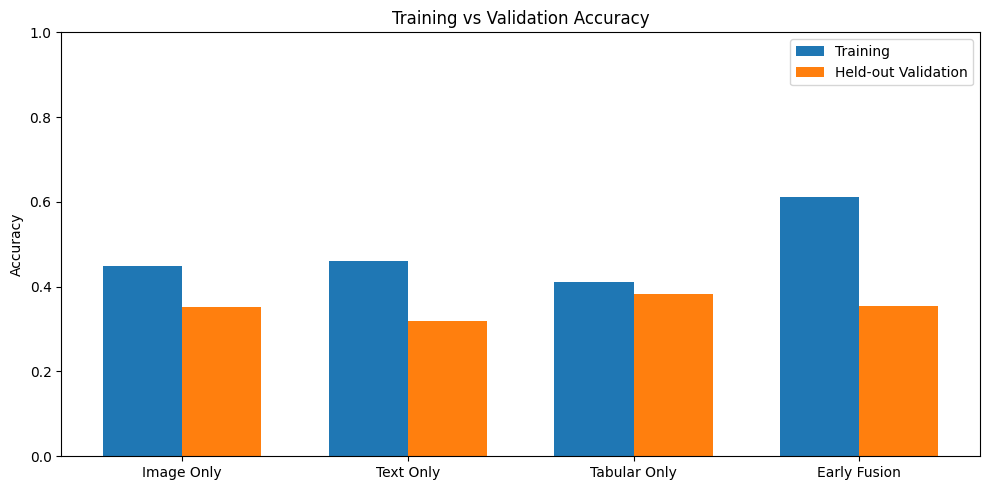

In [42]:
# Training vs Validation Accuracy

import matplotlib.pyplot as plt
import numpy as np

models = overfitting_df["Model"]
x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width/2,
    overfitting_df["Train Accuracy"],
    width,
    label="Training"
)

plt.bar(
    x + width/2,
    overfitting_df["Validation Accuracy"],
    width,
    label="Held-out Validation"
)

plt.xticks(x, models)
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    "overfitting_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [43]:
# Late Fusion Overfitting Assessment

from sklearn.metrics import accuracy_score, f1_score, log_loss
import numpy as np

# Calibration predictions
y_cal = y_val_array[cal_idx]

late_cal_pred = y_late_val_pred[cal_idx]

# Held-out validation predictions
y_eval = y_val_array[eval_idx]

late_eval_pred = y_late_val_pred[eval_idx]

# Calculate accuracy
cal_accuracy = accuracy_score(y_cal, late_cal_pred)
eval_accuracy = accuracy_score(y_eval, late_eval_pred)

# Calculate Macro F1
cal_f1 = f1_score(
    y_cal, late_cal_pred, average="macro"
)

eval_f1 = f1_score(
    y_eval, late_eval_pred, average="macro"
)

# Calculate log loss
cal_loss = log_loss(
    y_cal,
    late_val_proba[cal_idx],
    labels=classes
)

eval_loss = log_loss(
    y_eval,
    late_val_proba[eval_idx],
    labels=classes
)

print("Late Fusion Overfitting Assessment")

print("Calibration Accuracy:", round(cal_accuracy, 4))
print("Validation Accuracy:", round(eval_accuracy, 4))
print("Accuracy Gap:", round(cal_accuracy - eval_accuracy, 4))

print("Calibration Macro F1:", round(cal_f1, 4))
print("Validation Macro F1:", round(eval_f1, 4))
print("F1 Gap:", round(cal_f1 - eval_f1, 4))

print("Calibration Log Loss:", round(cal_loss, 4))
print("Validation Log Loss:", round(eval_loss, 4))

Late Fusion Overfitting Assessment
Calibration Accuracy: 0.4044
Validation Accuracy: 0.4126
Accuracy Gap: -0.0082
Calibration Macro F1: 0.3075
Validation Macro F1: 0.3126
F1 Gap: -0.0051
Calibration Log Loss: 1.3549
Validation Log Loss: 1.3579


We compare the training and validation performance to check for overfitting.

Early Fusion shows the largest Accuracy Gap 0.2589, which suggests strong overfitting. Tabular-only has the smallest gap 0.0298.

For Late Fusion, we compare calibration and held-out validation performance. The accuracy changes from 0.4044 to 0.4126, while Log Loss changes from 1.3549 to 1.3579.

The results do not show strong evidence of overfitting in the learned fusion weights, but the model still has limitations.

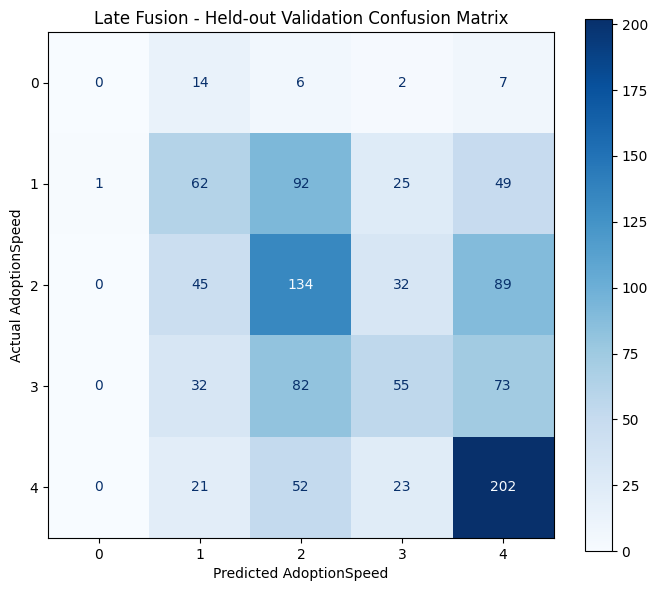

Late Fusion Classification Report
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        29
           1       0.36      0.27      0.31       229
           2       0.37      0.45      0.40       300
           3       0.40      0.23      0.29       242
           4       0.48      0.68      0.56       298

    accuracy                           0.41      1098
   macro avg       0.32      0.32      0.31      1098
weighted avg       0.39      0.41      0.39      1098



In [44]:
# Late Fusion Confusion Matrix

import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Confusion matrix on held-out validation data
cm = confusion_matrix(
    y_eval,
    late_eval_pred,
    labels=classes
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Late Fusion - Held-out Validation Confusion Matrix")
plt.xlabel("Predicted AdoptionSpeed")
plt.ylabel("Actual AdoptionSpeed")
plt.tight_layout()

plt.savefig(
    "late_fusion_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Classification report
print("Late Fusion Classification Report")

print(
    classification_report(
        y_eval,
        late_eval_pred,
        labels=classes,
        zero_division=0
    )
)

We use a confusion matrix and classification report to examine the predictions for each AdoptionSpeed class.

The model performs best for Class 4, with a recall of 0.68. However, Class 0 has a recall of 0.00, meaning none of the 29 samples in this class were correctly predicted.

This may be related to the small number of Class 0 samples. The results show that the model has difficulty predicting some adoption speed categories.

In [45]:
# Final Test Evaluation - Late Fusion

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    log_loss,
    classification_report
)

# Get test labels
y_test_array = np.asarray(y_test)
classes = np.array([0, 1, 2, 3, 4])

# Check test dataset sizes
assert len(X_image_test) == len(y_test_array)
assert len(X_text_test) == len(y_test_array)
assert X_tab_test.shape[0] == len(y_test_array)

# Check class order
for model in [image_model, text_model, tab_model]:
    assert np.array_equal(model.classes_, classes)

# Predict probabilities from three models
image_test_proba = image_model.predict_proba(X_image_test)

text_test_proba = text_model.predict_proba(X_text_test)

tab_test_proba = tab_model.predict_proba(X_tab_test)

# Combine probabilities using learned weights
late_test_proba = (
    late_weights[0] * image_test_proba
    + late_weights[1] * text_test_proba
    + late_weights[2] * tab_test_proba
)

# Final prediction
y_late_test_pred = classes[
    np.argmax(late_test_proba, axis=1)
]

# Calculate evaluation metrics
test_accuracy = accuracy_score(
    y_test_array, y_late_test_pred
)

test_macro_f1 = f1_score(
    y_test_array, y_late_test_pred,
    average="macro"
)

test_weighted_f1 = f1_score(
    y_test_array, y_late_test_pred,
    average="weighted"
)

test_qwk = cohen_kappa_score(
    y_test_array, y_late_test_pred,
    weights="quadratic"
)

test_log_loss = log_loss(
    y_test_array,
    late_test_proba,
    labels=classes
)

# Print final results
print("Late Fusion - Final Test Results")
print("Test Accuracy:", round(test_accuracy, 4))
print("Test Macro F1:", round(test_macro_f1, 4))
print("Test Weighted F1:", round(test_weighted_f1, 4))
print("Test QWK:", round(test_qwk, 4))
print("Test Log Loss:", round(test_log_loss, 4))

print("\nFinal Test Classification Report:")
print(
    classification_report(
        y_test_array,
        y_late_test_pred,
        labels=classes,
        zero_division=0
    )
)

Late Fusion - Final Test Results
Test Accuracy: 0.4044
Test Macro F1: 0.3154
Test Weighted F1: 0.3813
Test QWK: 0.3466
Test Log Loss: 1.3513

Final Test Classification Report:
              precision    recall  f1-score   support

           0       0.33      0.03      0.06        58
           1       0.37      0.29      0.32       458
           2       0.36      0.47      0.41       600
           3       0.36      0.17      0.23       483
           4       0.48      0.65      0.55       597

    accuracy                           0.40      2196
   macro avg       0.38      0.32      0.32      2196
weighted avg       0.39      0.40      0.38      2196



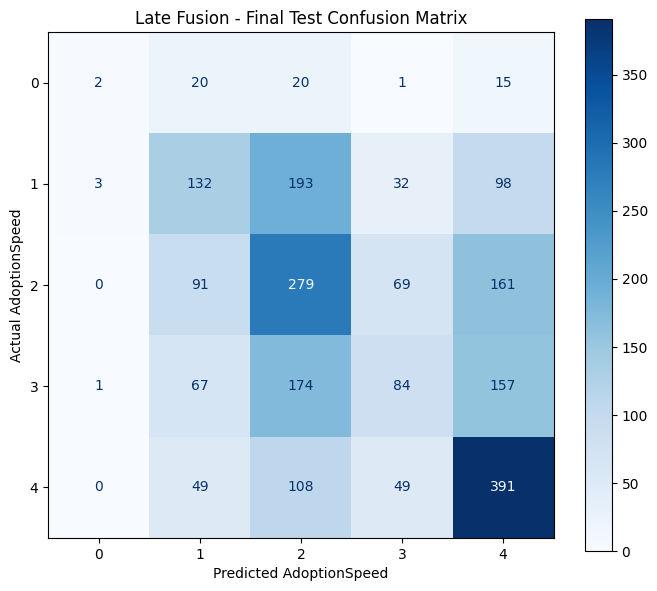

Final Test Confusion Matrix saved!


In [46]:
# Final Test Confusion Matrix

import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Calculate confusion matrix
cm_test = confusion_matrix(
    y_test_array,
    y_late_test_pred,
    labels=classes
)

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Late Fusion - Final Test Confusion Matrix")
plt.xlabel("Predicted AdoptionSpeed")
plt.ylabel("Actual AdoptionSpeed")

plt.tight_layout()

# Save figure to Google Drive
figure_dir = data_path / "report_figures"
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final Test Confusion Matrix saved!")

Late Fusion is selected as the final model based on the validation results.

We evaluate it on the independent test set containing 2,196 pets. The test accuracy is 0.4044, Macro F1 is 0.3154, and QWK is 0.3466.

The test results are close to the validation results, suggesting relatively consistent performance on unseen data.

However, Class 0 still has a very low recall of 0.03, while Class 4 has the highest recall of 0.65. This shows that the model is not equally accurate across all classes.

In [47]:
# Save Evaluation Results

import pandas as pd

# Create output folder
report_dir = data_path / "report_outputs"
report_dir.mkdir(parents=True, exist_ok=True)

# Save model comparison
comparison_df.to_csv(
    report_dir / "model_comparison.csv",
    index=False
)

# Save overfitting results
overfitting_df.to_csv(
    report_dir / "overfitting_results.csv",
    index=False
)

# Save final test metrics
final_test_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro F1",
        "Weighted F1",
        "QWK",
        "Log Loss"
    ],
    "Value": [
        test_accuracy,
        test_macro_f1,
        test_weighted_f1,
        test_qwk,
        test_log_loss
    ]
})

final_test_results.to_csv(
    report_dir / "final_test_results.csv",
    index=False
)

print("Results saved successfully!")
print("Saved to:", report_dir)

Results saved successfully!
Saved to: /content/drive/MyDrive/PetFinder/report_outputs


We save the model comparison results, overfitting assessment, and final test metrics as CSV files in Google Drive.

The results can be used to create tables and figures for the final report.

In [48]:
# Final Data Integrity Check

import numpy as np
from scipy import sparse

# Check train, validation and test separation
train_ids = set(train_df["PetID"].astype(str))
val_ids = set(val_df["PetID"].astype(str))
test_ids = set(test_df["PetID"].astype(str))

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("No PetID overlap between data splits.")

# Check image and text alignment
expected_ids = matched_df["PetID"].astype(str).to_numpy()

assert np.array_equal(image_ids, expected_ids)
assert np.array_equal(text_ids, expected_ids)

print("Image and text PetIDs are aligned.")

# Check invalid feature values
feature_sets = {
    "Image": X_image_all,
    "Text": X_text_all,
    "Tabular Train": X_tab_train,
    "Tabular Validation": X_tab_val,
    "Tabular Test": X_tab_test
}

for name, X in feature_sets.items():

    values = X.data if sparse.issparse(X) else np.asarray(X)

    assert np.isfinite(values).all(), f"Invalid values in {name}"

    print(name, "- no NaN or infinity.")

print("Final data integrity checks passed!")

No PetID overlap between data splits.
Image and text PetIDs are aligned.
Image - no NaN or infinity.
Text - no NaN or infinity.
Tabular Train - no NaN or infinity.
Tabular Validation - no NaN or infinity.
Tabular Test - no NaN or infinity.
Final data integrity checks passed!


We perform a final check to make sure the data is ready and correctly processed.

There is no PetID overlap between the training, validation, and test datasets. The image and text features are also correctly aligned.

We also check for missing or infinite values in the extracted features. No invalid values are found.

All final data integrity checks are passed.

In [49]:

# Save Trained Models

import joblib
import numpy as np

# Create folder in Google Drive
model_dir = data_path / "saved_models"
model_dir.mkdir(parents=True, exist_ok=True)

# Save classification models
joblib.dump(image_model, model_dir / "image_model.pkl")
joblib.dump(text_model, model_dir / "text_model.pkl")
joblib.dump(tab_model, model_dir / "tabular_model.pkl")
joblib.dump(early_model, model_dir / "early_fusion_model.pkl")

# Save preprocessing objects
joblib.dump(tab_preprocessor, model_dir / "tab_preprocessor.pkl")
joblib.dump(image_scaler, model_dir / "image_scaler.pkl")
joblib.dump(text_scaler, model_dir / "text_scaler.pkl")

# Save Late Fusion weights
np.save(model_dir / "late_fusion_weights.npy", late_weights)

# Save train / validation / test PetIDs
np.savez_compressed(
    model_dir / "data_split_ids.npz",
    train_ids=train_df["PetID"].astype(str).to_numpy(),
    val_ids=val_df["PetID"].astype(str).to_numpy(),
    test_ids=test_df["PetID"].astype(str).to_numpy()
)

print("All models and preprocessors saved successfully!")
print("Saved to:", model_dir)


All models and preprocessors saved successfully!
Saved to: /content/drive/MyDrive/PetFinder/saved_models


We save the trained classification models, preprocessing objects, and Late Fusion weights to Google Drive.

We also save the PetIDs used in the training, validation, and test datasets.

These files help us reuse the models and keep a record of the experiment without training the classifiers again.

### Ethics and Bias Assessment

There are some ethical and bias issues in this project.

First, the dataset has class imbalance. AdoptionSpeed 0 has fewer samples than the other classes, and the model has difficulty predicting this class.

Second, we only use pets with both images and text descriptions. This removes 353 pets from the original dataset and may introduce selection bias.

Also, pet images and descriptions may be different depending on how rescuers present the pets. This could affect the predictions.

The model should only be used to support adoption decisions, not replace human judgement.

### Final Summary

This project compares five models for predicting pet adoption speed using image, text, and tabular data.

Among the five models, Late Fusion achieves the best validation performance. Its final test accuracy is 0.4044, with a Macro F1 of 0.3154 and QWK of 0.3466.

The results show that combining different types of data can improve prediction performance compared with the single-modality models in this experiment.

However, the model still has difficulty predicting some classes, especially AdoptionSpeed 0.

In the future, we could try different classifiers, handle class imbalance, and explore other fusion methods to improve the results.